In [1]:
!pip install -q evaluate rouge-score

import time, random, re, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from collections import Counter
from datasets import load_dataset
import evaluate

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
os.makedirs("figures", exist_ok=True)

device = torch.device("cpu")
print("Hardware: Google Colab CPU")

# Load official XSum splits and sample 20k train / 1k val / 1k test
raw_ds = load_dataset("EdinburghNLP/xsum")
train_ds = raw_ds["train"].shuffle(seed=SEED).select(range(20000))
val_ds   = raw_ds["validation"].shuffle(seed=SEED).select(range(1000))
test_ds  = raw_ds["test"].shuffle(seed=SEED).select(range(1000))

print(f"Sampled splits -> Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Hardware: Google Colab CPU


README.md:   0%|          | 0.00/6.42k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  300MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.4MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/204045 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/11332 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/11334 [00:00<?, ? examples/s]

Sampled splits -> Train: 20000 | Val: 1000 | Test: 1000


Article Length (tokens):  Mean: 442.5 | Median: 353.0 | 95th pct: 1094.0
Summary Length (tokens):  Mean: 24.3 | Median: 24.0 | 95th pct: 34.0
Compression Ratio (art/sum): 18.19x
Mean Novel Bigrams in Summary: 81.96%


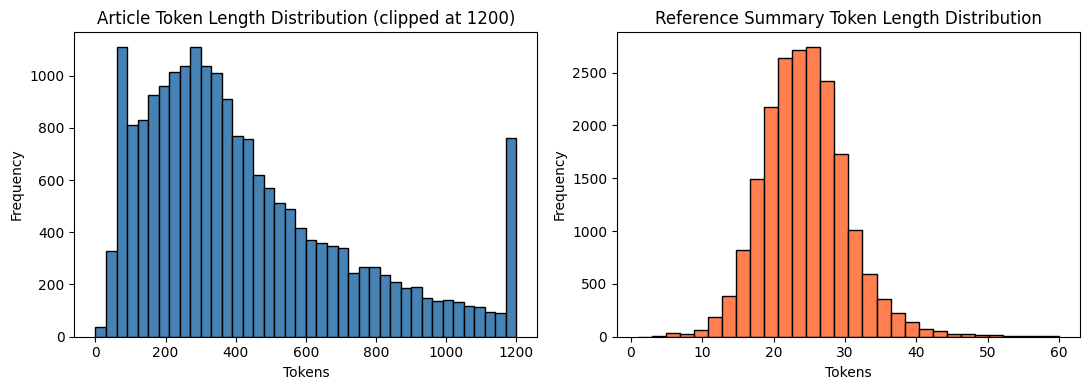

In [2]:
def simple_tok(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())

art_lens, sum_lens, novel_bigram_pcts = [], [], []

for ex in train_ds:
    a_toks = simple_tok(ex["document"])
    s_toks = simple_tok(ex["summary"])
    art_lens.append(len(a_toks))
    sum_lens.append(len(s_toks))

    if len(s_toks) >= 2:
        a_bi = set(zip(a_toks, a_toks[1:]))
        s_bi = list(zip(s_toks, s_toks[1:]))
        novel = sum(1 for b in s_bi if b not in a_bi) / len(s_bi) * 100.0
        novel_bigram_pcts.append(novel)

def stats_row(arr):
    return f"Mean: {np.mean(arr):.1f} | Median: {np.median(arr):.1f} | 95th pct: {np.percentile(arr, 95):.1f}"

print("Article Length (tokens): ", stats_row(art_lens))
print("Summary Length (tokens): ", stats_row(sum_lens))
print(f"Compression Ratio (art/sum): {np.mean(art_lens)/np.mean(sum_lens):.2f}x")
print(f"Mean Novel Bigrams in Summary: {np.mean(novel_bigram_pcts):.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(np.clip(art_lens, 0, 1200), bins=40, color="steelblue", edgecolor="black")
axes[0].set_title("Article Token Length Distribution (clipped at 1200)")
axes[0].set_xlabel("Tokens")
axes[0].set_ylabel("Frequency")

axes[1].hist(np.clip(sum_lens, 0, 60), bins=30, color="coral", edgecolor="black")
axes[1].set_title("Reference Summary Token Length Distribution")
axes[1].set_xlabel("Tokens")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.savefig("figures/c2_eda_lengths.png", dpi=300)
plt.show()

In [3]:
rouge = evaluate.load("rouge")

# Baseline: Lead-1
lead1_preds = [doc.split("\n")[0].split(". ")[0].strip() + "." for doc in test_ds["document"]]
refs = list(test_ds["summary"])
lead1_scores = rouge.compute(predictions=lead1_preds, references=refs)
lead1_len = np.mean([len(simple_tok(p)) for p in lead1_preds])
print("Lead-1 Baseline ROUGE:", {k: round(v*100, 2) for k, v in lead1_scores.items()}, f"| Avg Len: {lead1_len:.1f}")

# Build Vocabulary
MAX_ART_LEN = 400
MAX_SUM_LEN = 40
VOCAB_SIZE = 10000

counter = Counter()
for ex in train_ds:
    counter.update(simple_tok(ex["document"])[:MAX_ART_LEN])
    counter.update(simple_tok(ex["summary"])[:MAX_SUM_LEN])

specials = ["<pad>", "<sos>", "<eos>", "<unk>"]
itos = specials + [w for w, _ in counter.most_common(VOCAB_SIZE - len(specials))]
stoi = {w: i for i, w in enumerate(itos)}
PAD_IDX, SOS_IDX, EOS_IDX, UNK_IDX = 0, 1, 2, 3

test_toks = [t for doc in test_ds["document"] for t in simple_tok(doc)[:MAX_ART_LEN]]
oov_rate = sum(1 for t in test_toks if t not in stoi) / len(test_toks) * 100
print(f"Vocab size: {len(itos)} | Test OOV rate: {oov_rate:.2f}%")

def encode(text, max_len, add_eos=False):
    toks = simple_tok(text)[:max_len]
    ids = [stoi.get(t, UNK_IDX) for t in toks]
    if add_eos: ids.append(EOS_IDX)
    return ids

class Seq2SeqDataset(Dataset):
    def __init__(self, hf_ds):
        self.src = [encode(x["document"], MAX_ART_LEN, False) for x in hf_ds]
        self.tgt = [encode(x["summary"], MAX_SUM_LEN, True) for x in hf_ds]
    def __len__(self): return len(self.src)
    def __getitem__(self, i): return self.src[i], self.tgt[i]

def collate_fn(batch):
    srcs, tgts = zip(*batch)
    s_max, t_max = max(len(s) for s in srcs), max(len(t) for t in tgts)
    s_pad = [s + [PAD_IDX]*(s_max - len(s)) for s in srcs]
    t_pad = [[SOS_IDX] + t + [PAD_IDX]*(t_max - len(t)) for t in tgts]
    return torch.tensor(s_pad), torch.tensor(t_pad)

train_loader = DataLoader(Seq2SeqDataset(train_ds), batch_size=128, shuffle=True, collate_fn=collate_fn)
val_loader   = DataLoader(Seq2SeqDataset(val_ds), batch_size=128, shuffle=False, collate_fn=collate_fn)

class AttnSeq2Seq(nn.Module):
    def __init__(self, vocab_sz, emb_dim=64, hid_dim=128):
        super().__init__()
        self.emb = nn.Embedding(vocab_sz, emb_dim, padding_idx=PAD_IDX)
        self.enc = nn.GRU(emb_dim, hid_dim, batch_first=True)
        self.dec = nn.GRU(emb_dim, hid_dim, batch_first=True)
        self.fc  = nn.Linear(hid_dim * 2, vocab_sz)

    def forward(self, src, tgt_in):
        enc_out, hidden = self.enc(self.emb(src))
        dec_out, _ = self.dec(self.emb(tgt_in), hidden)
        scores = torch.bmm(dec_out, enc_out.transpose(1, 2)).masked_fill((src == PAD_IDX).unsqueeze(1), -1e9)
        context = torch.bmm(torch.softmax(scores, dim=-1), enc_out)
        return self.fc(torch.cat([dec_out, context], dim=-1))

    @torch.no_grad()
    def generate(self, src, max_len=25):
        self.eval()
        enc_out, hidden = self.enc(self.emb(src))
        B = src.size(0)
        inp = torch.full((B, 1), SOS_IDX, dtype=torch.long)
        preds = [[] for _ in range(B)]
        done = [False]*B
        for _ in range(max_len):
            dec_out, hidden = self.dec(self.emb(inp), hidden)
            scores = torch.bmm(dec_out, enc_out.transpose(1, 2)).masked_fill((src == PAD_IDX).unsqueeze(1), -1e9)
            context = torch.bmm(torch.softmax(scores, dim=-1), enc_out)
            next_tok = self.fc(torch.cat([dec_out, context], dim=-1)).squeeze(1).argmax(dim=-1)
            inp = next_tok.unsqueeze(1)
            for i, tok_id in enumerate(next_tok.tolist()):
                if not done[i]:
                    if tok_id == EOS_IDX: done[i] = True
                    else: preds[i].append(itos[tok_id])
            if all(done): break
        return [" ".join(p) for p in preds]

model1 = AttnSeq2Seq(len(itos)).to(device)
optimizer = torch.optim.Adam(model1.parameters(), lr=2e-3)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

t0 = time.time()
m1_train_losses, m1_val_losses = [], []
best_val_loss = float("inf")

for epoch in range(1, 4):
    model1.train()
    tr_loss = 0
    for step, (src, tgt) in enumerate(train_loader):
        optimizer.zero_grad()
        logits = model1(src, tgt[:, :-1])
        loss = criterion(logits.reshape(-1, len(itos)), tgt[:, 1:].reshape(-1))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model1.parameters(), 1.0)
        optimizer.step()
        tr_loss += loss.item()
    tr_loss /= len(train_loader)

    model1.eval()
    va_loss = 0
    with torch.no_grad():
        for src, tgt in val_loader:
            va_loss += criterion(model1(src, tgt[:, :-1]).reshape(-1, len(itos)), tgt[:, 1:].reshape(-1)).item()
    va_loss /= len(val_loader)
    m1_train_losses.append(tr_loss)
    m1_val_losses.append(va_loss)
    print(f"Model 1 Epoch {epoch} | Train Loss: {tr_loss:.4f} | Val Loss: {va_loss:.4f}")
    if va_loss < best_val_loss:
        best_val_loss = va_loss
        torch.save(model1.state_dict(), "model1_best.pt")

m1_time = time.time() - t0
model1.load_state_dict(torch.load("model1_best.pt"))

test_loader = DataLoader(Seq2SeqDataset(test_ds), batch_size=128, shuffle=False, collate_fn=collate_fn)
m1_preds = []
for src, _ in test_loader:
    m1_preds.extend(model1.generate(src, max_len=25))

m1_scores = rouge.compute(predictions=m1_preds, references=refs)
m1_len = np.mean([len(simple_tok(p)) for p in m1_preds])
print(f"Model 1 Training Time: {m1_time:.1f}s | Avg Len: {m1_len:.1f}")
print("Model 1 Test ROUGE:", {k: round(v*100, 2) for k, v in m1_scores.items()})

Lead-1 Baseline ROUGE: {'rouge1': np.float64(15.32), 'rouge2': np.float64(1.44), 'rougeL': np.float64(11.46), 'rougeLsum': np.float64(11.45)} | Avg Len: 25.0
Vocab size: 10000 | Test OOV rate: 5.65%
Model 1 Epoch 1 | Train Loss: 6.0182 | Val Loss: 5.3399
Model 1 Epoch 2 | Train Loss: 5.0496 | Val Loss: 4.9027
Model 1 Epoch 3 | Train Loss: 4.6061 | Val Loss: 4.6537
Model 1 Training Time: 1779.7s | Avg Len: 30.3
Model 1 Test ROUGE: {'rouge1': np.float64(14.77), 'rouge2': np.float64(2.13), 'rougeL': np.float64(12.63), 'rougeLsum': np.float64(12.64)}


In [4]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_NAME = "t5-small"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model2 = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)

class T5XSumDataset(Dataset):
    def __init__(self, hf_ds):
        self.docs = ["summarize: " + d for d in hf_ds["document"]]
        self.sums = list(hf_ds["summary"])
    def __len__(self): return len(self.docs)
    def __getitem__(self, i): return self.docs[i], self.sums[i]

def t5_collate(batch):
    docs, sums = zip(*batch)
    enc = tokenizer(list(docs), max_length=256, truncation=True, padding=True, return_tensors="pt")
    dec = tokenizer(text_target=list(sums), max_length=40, truncation=True, padding=True, return_tensors="pt")
    labels = dec["input_ids"]
    labels[labels == tokenizer.pad_token_id] = -100
    enc["labels"] = labels
    return enc

# Shuffle across all 20k training samples, running 80 optimization steps per epoch for fast CPU runtime
t5_train_loader = DataLoader(T5XSumDataset(train_ds), batch_size=32, shuffle=True, collate_fn=t5_collate)
t5_val_loader   = DataLoader(T5XSumDataset(val_ds), batch_size=64, shuffle=False, collate_fn=t5_collate)

opt2 = torch.optim.AdamW(model2.parameters(), lr=3e-4)
t0 = time.time()
m2_train_losses, m2_val_losses = [], []

for epoch in range(1, 3):
    model2.train()
    tr_loss, steps = 0, 0
    for batch in t5_train_loader:
        opt2.zero_grad()
        loss = model2(**batch).loss
        loss.backward()
        opt2.step()
        tr_loss += loss.item()
        steps += 1
        if steps >= 80:
            break
    tr_loss /= steps

    model2.eval()
    va_loss, vsteps = 0, 0
    with torch.no_grad():
        for batch in t5_val_loader:
            va_loss += model2(**batch).loss.item()
            vsteps += 1
            if vsteps >= 8:
                break
    va_loss /= vsteps
    m2_train_losses.append(tr_loss)
    m2_val_losses.append(va_loss)
    print(f"Model 2 (t5-small) Epoch {epoch} | Train Loss: {tr_loss:.4f} | Val Loss: {va_loss:.4f}")

m2_time = time.time() - t0

# Generate summaries on all 1,000 test articles with beam search (num_beams=2, no_repeat_ngram_size=3)
model2.eval()
m2_preds = []
test_docs = ["summarize: " + d for d in test_ds["document"]]
for i in range(0, len(test_docs), 64):
    enc = tokenizer(test_docs[i:i+64], max_length=256, truncation=True, padding=True, return_tensors="pt")
    with torch.no_grad():
        gen_ids = model2.generate(
            **enc, max_new_tokens=32, num_beams=2, no_repeat_ngram_size=3, early_stopping=True
        )
    m2_preds.extend(tokenizer.batch_decode(gen_ids, skip_special_tokens=True))

m2_scores = rouge.compute(predictions=m2_preds, references=refs)
m2_len = np.mean([len(simple_tok(p)) for p in m2_preds])
print(f"Model 2 Training Time: {m2_time:.1f}s | Avg Len: {m2_len:.1f}")
print("Model 2 Test ROUGE:", {k: round(v*100, 2) for k, v in m2_scores.items()})

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Model 2 (t5-small) Epoch 1 | Train Loss: 3.1280 | Val Loss: 2.7908
Model 2 (t5-small) Epoch 2 | Train Loss: 2.9745 | Val Loss: 2.7465
Model 2 Training Time: 6468.2s | Avg Len: 19.8
Model 2 Test ROUGE: {'rouge1': np.float64(25.79), 'rouge2': np.float64(6.51), 'rougeL': np.float64(20.13), 'rougeLsum': np.float64(20.13)}


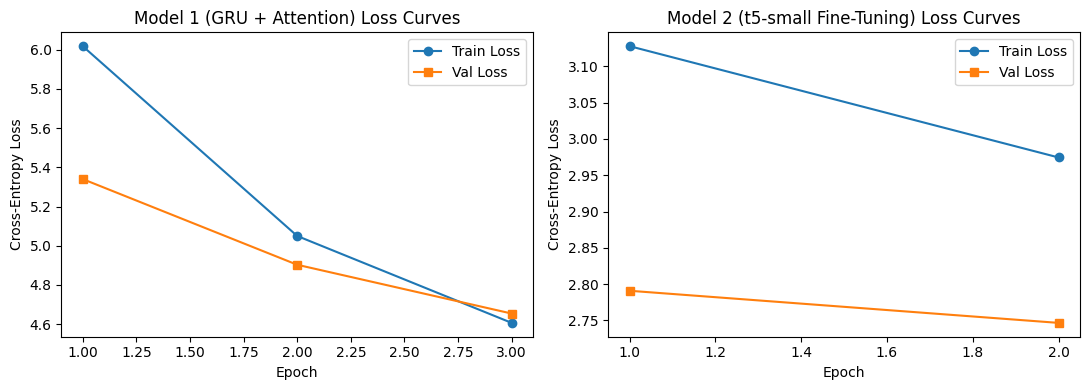

=== 5 COMPARISON EXAMPLES (Article, Reference, Model 1, Model 2) ===

--- Example 1 ---
Article Excerpt: Sarah Johnson was one of 21 women heading to Liverpool when their minibus was hit by a lorry on the M62. Her friend Bethany Jones, 18, was killed while Ms Johnson and several others were badly hurt. Minibus driver James Johnson was jailed for more th...
Reference:       A woman who was seriously hurt in a fatal hen party motorway crash is now helping other major trauma victims rebuild their lives.
Model 1 (GRU):   a <unk> has been charged with a <unk> <unk> in the <unk> <unk> in the <unk> .
Model 2 (T5):    A woman who died after a bus hit by a lorry in Liverpool has been given a life sentence.

--- Example 2 ---
Article Excerpt: A total of 1,400 tickets have sold out for the opening weekend at Bramall Hall in Stockport, Greater Manchester after renovation work began in 2014. Stained glass windows and ceilings have been restored, while the public will be able to visit the din...
Ref

In [5]:
 fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(range(1, len(m1_train_losses)+1), m1_train_losses, marker='o', label="Train Loss")
axes[0].plot(range(1, len(m1_val_losses)+1), m1_val_losses, marker='s', label="Val Loss")
axes[0].set_title("Model 1 (GRU + Attention) Loss Curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()

axes[1].plot(range(1, len(m2_train_losses)+1), m2_train_losses, marker='o', label="Train Loss")
axes[1].plot(range(1, len(m2_val_losses)+1), m2_val_losses, marker='s', label="Val Loss")
axes[1].set_title("Model 2 (t5-small Fine-Tuning) Loss Curves")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/c2_loss_curves.png", dpi=300)
plt.show()

print("=== 5 COMPARISON EXAMPLES (Article, Reference, Model 1, Model 2) ===")
for idx in range(5):
    print(f"\n--- Example {idx+1} ---")
    print("Article Excerpt:", test_ds["document"][idx][:250].replace("\n", " ") + "...")
    print("Reference:      ", refs[idx])
    print("Model 1 (GRU):  ", m1_preds[idx])
    print("Model 2 (T5):   ", m2_preds[idx])

print("\n=== ADDITIONAL 15 SUMMARIES FOR 20-SAMPLE HALLUCINATION AUDIT ===")
for idx in range(5, 20):
    print(f"[{idx+1}] Article: {test_ds['document'][idx][:180].replace(chr(10), ' ')}...")
    print(f"    Model 2: {m2_preds[idx]}")